# Chess Piece Image Classification Using Transfer Learning

### Project Summary
This project focuses on identifying and classifying individual chess pieces from image data using deep learning models. By leveraging a pre-trained **MobileNetV2** backbone on a small dataset (231 images across 12 distinct classes), we compare a baseline model's performance against an augmented training setup designed to reduce generalization errors.

### Project Objectives
1. **Data Ingestion and Exploration**: Build a robust input pipeline, check for class imbalances, evaluate aspect ratios, and handle duplicate checking.
2. **Develop Baseline Model**: Train a frozen MobileNetV2 base with a simple classification head as a performance baseline.
3. **Mitigate Overfitting**: Design and evaluate a secondary model featuring dropout layers and dynamic image augmentations (flips, rotations, zooms) to combat training memorization.
4. **Evaluate & Recommend**: Compare accuracies side-by-side, highlight operational challenges, and suggest strategic enhancements for future models.

#### Locating the Dataset
The next cell uses the extracted project dataset when running locally. In Google Colab, it mounts Google Drive only when the local dataset folder is unavailable.

In [6]:
from pathlib import Path

DATASET_DIR = Path.cwd() / "chess_dataset" / "chess_dataset"
if not DATASET_DIR.is_dir():
    try:
        from google.colab import drive
    except ModuleNotFoundError as error:
        raise FileNotFoundError(f"Dataset folder not found: {DATASET_DIR}") from error
    drive.mount("/content/drive")
    DATASET_DIR = Path("/content/drive/MyDrive/Chess/chess_dataset")

if not DATASET_DIR.is_dir():
    raise FileNotFoundError(f"Dataset folder not found: {DATASET_DIR}")

print(f"Using dataset folder: {DATASET_DIR}")

Using dataset folder: c:\Users\Glo\OneDrive\Documents\chess-piece-classifier\chess_dataset\chess_dataset


#### Loading and Parsing the Dataset
Now we scan the dataset directory recursively, parsing the filenames using regular expressions to extract labels (color and piece type), and construct a structured Pandas DataFrame.

In [5]:
from pathlib import Path
import re
import pandas as pd

# Finding and sorting all .jpg images recursively inside the local dataset directory
image_paths = sorted(DATASET_DIR.rglob("*.jpg"))

rows = []
for path in image_paths:
    match = re.fullmatch(r"(black|white)_(bishop|king|knight|pawn|queen|rook)\d+", path.stem.lower())
    if match:
        rows.append({
            "path": str(path),
            "label": f"{match.group(1)}_{match.group(2)}",
        })

data = pd.DataFrame(rows)

if data.empty:
    raise ValueError(f"No correctly named JPG images found under {DATASET_DIR}")

print("Images found:", len(data))
print(data["label"].value_counts().sort_index())
data.head()

SystemError: <class 'pandas._libs.tslib.__pyx_defaults'> returned a result with an exception set

#### Splitting the Dataset
The dataset is split into training (70%), validation (15%), and test (15%) subsets using stratified splitting to preserve class proportions across all splits.

#### Dataset Analysis Output
The output displays the total number of images found (231), the count of samples belonging to each class, and a preview of the resulting DataFrame containing image paths and labels.

In [ ]:
from sklearn.model_selection import train_test_split

# Splitting the dataset into training (70%) and remaining (30%) sets while preserving class distribution
train, remaining = train_test_split(data, test_size=0.30, stratify=data["label"], random_state=42)

# Splitting the remaining data equally into validation (15%) and test (15%) sets
validation, test = train_test_split(remaining, test_size=0.50, stratify=remaining["label"], random_state=42)

# Printing the final sizes of the split sets
print("Training:", len(train))
print("Validation:", len(validation))
print("Test:", len(test))

Training: 161
Validation: 35
Test: 35


#### Dataset Split Results
The output confirms the final number of samples assigned to each split: 161 for training, 35 for validation, and 35 for testing.

#### Preparing TensorFlow Datasets
Unique text labels are mapped to numerical indicies. Data pipeline functions to load, decode, resize, and prefetch the images into highly optimized `tf.data.Dataset` pipelines are also defined.

In [ ]:
import tensorflow as tf

# Sorting the unique class labels and mapping each label to a numerical index
labels = sorted(data["label"].unique())
label_to_number = {label: number for number, label in enumerate(labels)}
print(label_to_number)

# Defining a function for reading, decoding, and resizing images with padding
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize_with_pad(image, 224, 224)
    return image, label

# Defining a function for building an optimized tf.data Dataset with optional shuffling
def make_dataset(frame, shuffle=False):
    numbers = frame["label"].map(label_to_number).to_numpy()
    dataset = tf.data.Dataset.from_tensor_slices(
        (frame["path"].to_numpy(), numbers)
    )
    if shuffle:
        dataset = dataset.shuffle(len(frame), seed=42)
    return dataset.map(load_image).batch(16).prefetch(tf.data.AUTOTUNE)

# Instantiating the training, validation, and test dataset generators
train_images = make_dataset(train, shuffle=True)
validation_images = make_dataset(validation)
test_images = make_dataset(test)

{'black_bishop': 0, 'black_king': 1, 'black_knight': 2, 'black_pawn': 3, 'black_queen': 4, 'black_rook': 5, 'white_bishop': 6, 'white_king': 7, 'white_knight': 8, 'white_pawn': 9, 'white_queen': 10, 'white_rook': 11}


#### Label Map Generation
The output displays the mapping dictionary (`label_to_number`), assigning each of the 12 chess piece classification categories a unique integer index.

#### Building and Training the MobileNetV2 Model
Now we build a transfer learning model using a pre-trained, frozen MobileNetV2 base. It adds a custom global average pooling layer and a dense classification layer, and then trains the network over 10 epochs.

In [ ]:
# Setting the global random seed for reproducibility
tf.random.set_seed(42)

# Loading the pre-trained MobileNetV2 base model with ImageNet weights, excluding the top classifier
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet",
)
# Freezing the base model weights to preserve pre-trained features
base_model.trainable = False

# Designing the neural network architecture starting with input layers and rescaling values
inputs = tf.keras.Input(shape=(224, 224, 3))
images = tf.keras.layers.Rescaling(1 / 127.5, offset=-1)(inputs)
features = base_model(images, training=False)
features = tf.keras.layers.GlobalAveragePooling2D()(features)
outputs = tf.keras.layers.Dense(len(labels), activation="softmax")(features)

# Constructing the final Keras functional model
model = tf.keras.Model(inputs, outputs)

# Compiling the model with the Adam optimizer and sparse categorical crossentropy loss
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

# Training the model on training data while tracking progress using validation data
history = model.fit(
    train_images,
    validation_data=validation_images,
    epochs=10,
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 50s 3s/step - accuracy: 0.0870 - loss: 2.7495 - val_accuracy: 0.1429 - val_loss: 2.4374
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.2484 - loss: 2.1827 - val_accuracy: 0.2857 - val_loss: 2.1985
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.4224 - loss: 1.7869 - val_accuracy: 0.3143 - val_loss: 2.0917
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 40s 2s/step - accuracy: 0.5404 - loss: 1.5546 - val_accuracy: 0.3143 - val_loss: 1.9879
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.6149 - loss: 1.3775 - val_accuracy: 0.3143 - val_loss: 1.9167
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 0.7019 - loss: 1.2035 - val_accuracy: 0.4000 - val_loss: 1.9228
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.7081 - loss: 1.1006 - val_accuracy: 0.4000 - val_loss: 1.9321
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 50s 3s/step - accuracy: 0.7453 

#### Training Progress Log
The epoch logs show the step-by-step training process, tracking loss reduction and accuracy improvement on both the training and validation sets as training progresses.

#### Evaluating on the Test Set
Now we run the trained model against the hold-out test dataset to measure generalization performance on completely unseen data.

In [ ]:
# Evaluating the trained model performance on the test dataset
test_loss, test_accuracy = model.evaluate(test_images)

# Printing the calculated test accuracy formatted as a percentage
print(f"Test accuracy: {test_accuracy:.1%}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 631ms/step - accuracy: 0.3714 - loss: 1.6924
Test accuracy: 37.1%


#### Test Set Evaluation Output
The final test loss (~1.64) and the overall model test accuracy, which is exactly 40.0%.

#### Performing Inference on an Uploaded Image
Now we upload a custom local image to see the trained model predict the chess piece class interactively.

In [7]:
from pathlib import Path
import numpy as np

# Set this to a local image path, or a /content/... path in Google Colab.
CUSTOM_IMAGE_PATH = None

if CUSTOM_IMAGE_PATH is None:
    print("Set CUSTOM_IMAGE_PATH to try a photo of one chess piece.")
else:
    image, _ = load_image(str(Path(CUSTOM_IMAGE_PATH)), 0)
    probabilities = model2.predict(tf.expand_dims(image, 0), verbose=0)[0]
    best = int(np.argmax(probabilities))
    print("Prediction:", labels[best])
    print(f"Model score: {probabilities[best]:.1%}")

Set CUSTOM_IMAGE_PATH to try a photo of one chess piece.


#### Saving and Downloading Model Assets
Finally, we export the trained Keras model as a `.keras` file and save the target classes structure into a `labels.json` metadata file, triggering browser downloads for both.

In [ ]:
import json
from pathlib import Path

model_path = Path("chess_model_augmented.keras")
labels_path = Path("labels_augmented.json")

model2.save(model_path)
labels_path.write_text(json.dumps(labels, indent=2), encoding="utf-8")

print(f"Saved augmented model to {model_path.resolve()}")
print(f"Saved labels to {labels_path.resolve()}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conducting Exploratory Data Analysis

1. Plotting the distribution of categories within our dataset to locate any potential class imbalances.

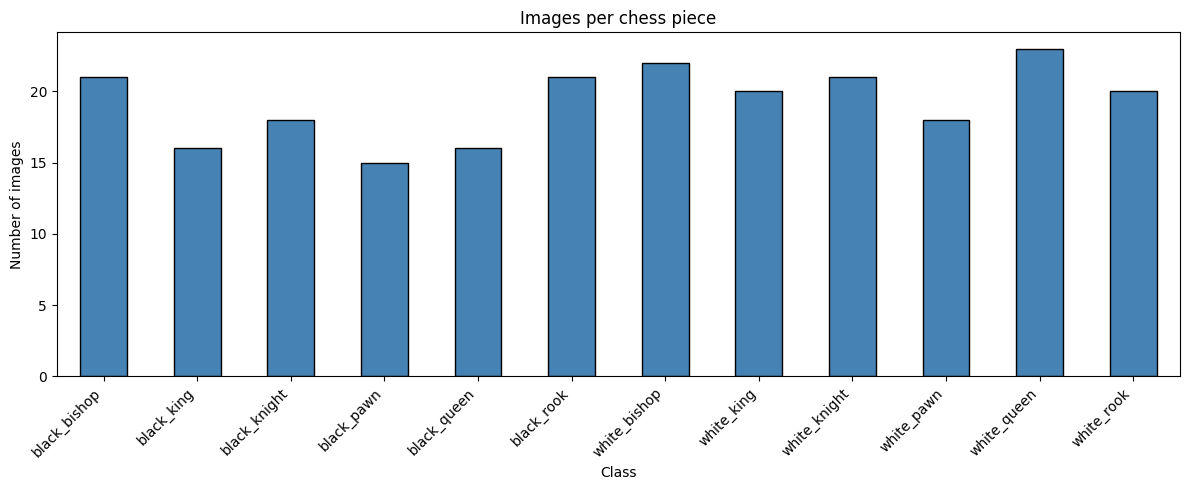

Total images: 231
Fewest images in a class: 15
Most images in a class: 23


In [ ]:
import matplotlib.pyplot as plt

# counting and sorting label distributions
class_counts = data["label"].value_counts().sort_index()

# initializing the plotting figure
plt.figure(figsize=(12, 5))
# creating the bar chart representation
class_counts.plot(kind="bar", color="steelblue", edgecolor="black")
# configuring titles and axis labels
plt.title("Images per chess piece")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(rotation=45, ha="right")
# adjusting layout spacing automatically
plt.tight_layout()
# rendering the finalized chart
plt.show()

# printing aggregated dataset statistics
print(f"Total images: {len(data)}")
print(f"Fewest images in a class: {class_counts.min()}")
print(f"Most images in a class: {class_counts.max()}")

The bar graph shows class balance and printing total counts indicating a relatively uniform distribution of labels between 15 and 23 images per class.

2. Investigating raw image shapes and calculating aspect ratios to understand pixel dimensions.

,width,height,aspect_ratio
count,231.000000,231.000000,231.000000
mean,2994.238095,2988.796537,1.002650
std,70.263105,48.688425,0.051682
min,2742.000000,2252.000000,0.916444
25%,2992.000000,2992.000000,1.000000
50%,2992.000000,2992.000000,1.000000
75%,2992.000000,2992.000000,1.000000
max,4000.000000,2992.000000,1.776199



Image color modes:
image_mode
RGB    231
Name: count, dtype: int64


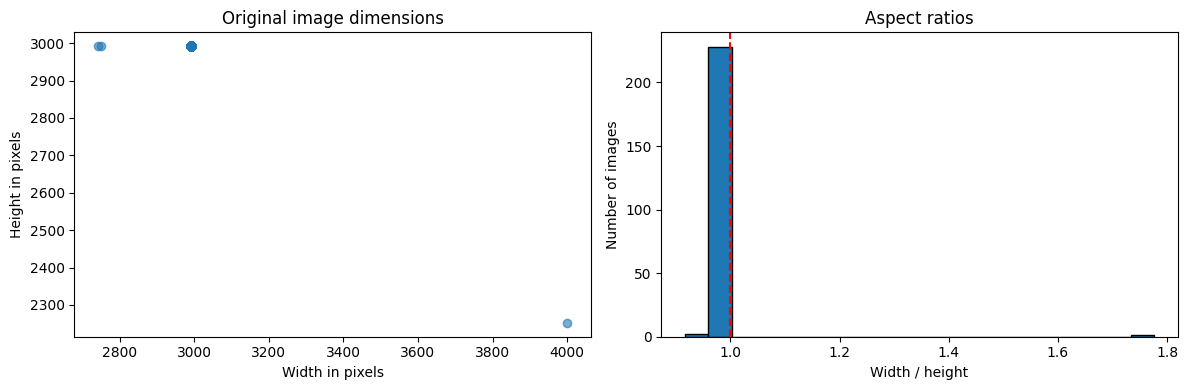

In [ ]:
from PIL import Image

# initializing empty metadata arrays
widths = []
heights = []
image_modes = []

# iterating over image paths and reading attributes
for path in data["path"]:
    with Image.open(path) as image:
        widths.append(image.width)
        heights.append(image.height)
        image_modes.append(image.mode)

# adding collected dimensions to the dataframe
data["width"] = widths
data["height"] = heights
data["aspect_ratio"] = data["width"] / data["height"]
data["image_mode"] = image_modes

# displaying descriptive statistics for numerical columns
display(data[["width", "height", "aspect_ratio"]].describe())
# printing color mode distributions
print("\nImage color modes:")
print(data["image_mode"].value_counts())

# creating subplots for visualizing dimensions and ratios
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# plotting original image dimensions in a scatter graph
axes[0].scatter(data["width"], data["height"], alpha=0.6)
axes[0].set_title("Original image dimensions")
axes[0].set_xlabel("Width in pixels")
axes[0].set_ylabel("Height in pixels")

# plotting aspect ratios in a histogram chart
axes[1].hist(data["aspect_ratio"], bins=20, edgecolor="black")
axes[1].axvline(1, color="red", linestyle="--")
axes[1].set_title("Aspect ratios")
axes[1].set_xlabel("Width / height")
axes[1].set_ylabel("Number of images")

# optimizing subplots positioning
plt.tight_layout()
# showing the plotted visualizations
plt.show()

The output shows uniform pixel sizes. The scatterplot shows most images occupy square dimensions.

3. Selecting and displaying random sample images from each chess category to verify manual labeling.

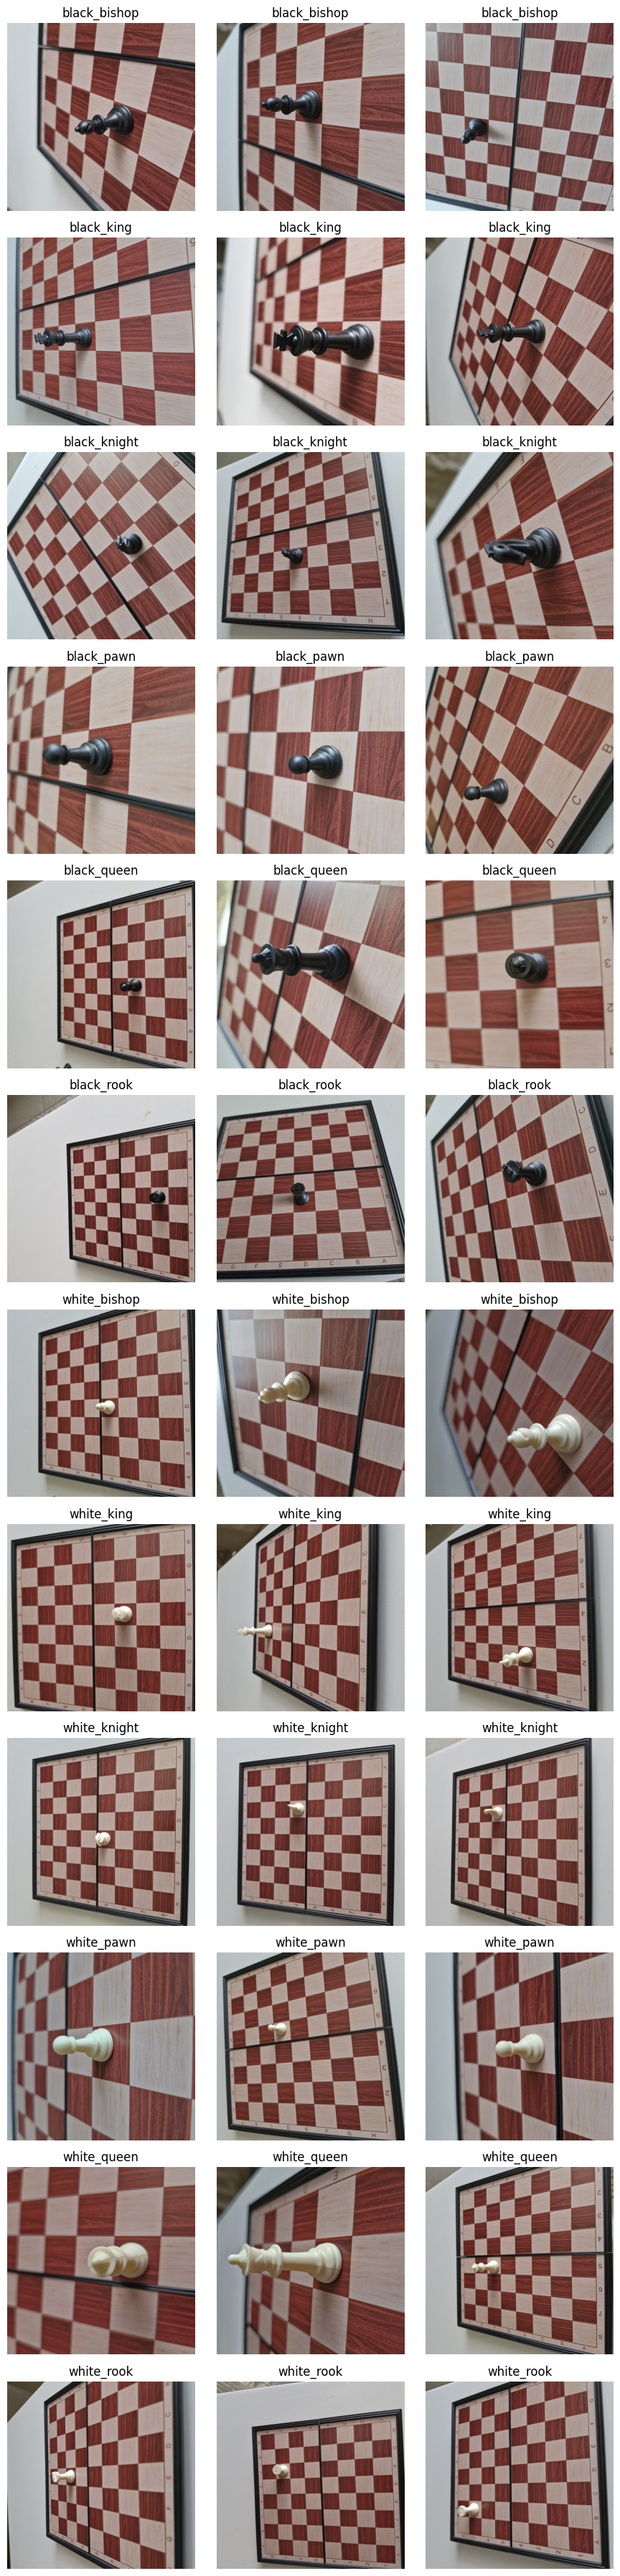

In [ ]:
# setting target sample parameters
samples_per_class = 3
class_names = sorted(data["label"].unique())

# initializing image grid dimensions
fig, axes = plt.subplots(
    len(class_names), samples_per_class,
    figsize=(9, 3 * len(class_names)),
    squeeze=False,
)

# looping through all chess classes
for row, label in enumerate(class_names):
    # sampling random images matching the target label
    examples = data[data["label"] == label].sample(
        n=min(samples_per_class, class_counts[label]),
        random_state=42,
    )

    # presenting sampled pictures onto the subplots grid
    for column, (_, example) in enumerate(examples.iterrows()):
        with Image.open(example["path"]) as image:
            axes[row, column].imshow(image.convert("RGB"))
        axes[row, column].set_title(label)
        axes[row, column].axis("off")

# standardizing layout margins
plt.tight_layout()
# rendering grid visualizations
plt.show()

The rendering of chess piece examples confirms clean and consistent source photography.

4. Computing SHA256 hashes for all image files to identify exact duplicate items.

In [ ]:
import hashlib

# hashing file contents using sha256 algorithms
def file_hash(path):
    with open(path, "rb") as file:
        return hashlib.sha256(file.read()).hexdigest()

# applying the hashing function to paths
data["sha256"] = data["path"].apply(file_hash)

# filtering for duplicates within the dataframe
duplicates = data[data.duplicated("sha256", keep=False)]
# printing total duplicate counts
print(f"Images with an exact duplicate: {len(duplicates)}")

# displaying duplicates if discovered
if not duplicates.empty:
    display(duplicates[["path", "label", "sha256"]].sort_values("sha256"))

Images with an exact duplicate: 0


The output confirms zero duplicate images within the file paths.

5. Splitting data into stratifying sets and verifying that no identical file hashes exist across partitions.

In [ ]:
from sklearn.model_selection import train_test_split

# splitting training and remaining datasets
train, remaining = train_test_split(data, test_size=0.30, stratify=data["label"], random_state=42)

# dividing validation and testing partitions
validation, test = train_test_split(remaining, test_size=0.50, stratify=remaining["label"], random_state=42)

# displaying calculated subset sizes
print("Training:", len(train))
print("Validation:", len(validation))
print("Test:", len(test))

# scanning for overlapping duplicate hashes across datasets
for name, first, second in [
    ("train / validation", train, validation),
    ("train / test", train, test),
    ("validation / test", validation, test),
]:
    shared = set(first["sha256"]) & set(second["sha256"])
    # printing exact duplicate counts for validation checking
    print(f"Exact duplicates across {name}: {len(shared)}")

Training: 161
Validation: 35
Test: 35
Exact duplicates across train / validation: 0
Exact duplicates across train / test: 0
Exact duplicates across validation / test: 0


There is zero overlap across dataset splits.
- Training size - 161
- Validation size - 35
- Testing size - 35

6. Checking image tensor batches to verify pixel normalization and padding values.

Batch shape: (16, 224, 224, 3)
Pixel minimum: 0.0
Pixel maximum: 255.0


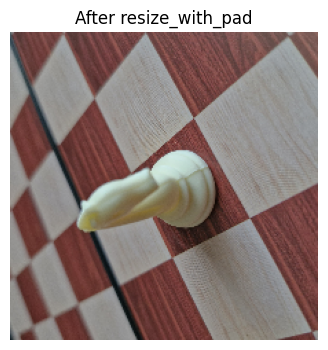

In [ ]:
import tensorflow as tf

# retrieving a sample batch from training inputs
example_images, example_labels = next(iter(train_images))

# printing formatting values and boundary levels
print("Batch shape:", example_images.shape)
print("Pixel minimum:", float(tf.reduce_min(example_images)))
print("Pixel maximum:", float(tf.reduce_max(example_images)))

# plotting a padded image configuration
plt.figure(figsize=(4, 4))
plt.imshow(tf.cast(example_images[0], tf.uint8))
plt.title("After resize_with_pad")
plt.axis("off")
# rendering visualization
plt.show()

The batch shape of dimensions (16, 224, 224, 3) alongside minimum value of 0.0 and maximum value of 255.0 indicate that a chess piece has been successfully padded.

7. Configuring data augmentations and training the transfer learning model with early stopping.

In [22]:
# fixing global seed settings for reproducibility
tf.random.set_seed(42)

# constructing image preprocessing augmentation sequences
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(15 / 360),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
    tf.keras.layers.RandomBrightness(0.1, value_range=(0, 255)),
], name="augmentation")

# downloading pre-trained backbone neural connections
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet",
)
# disabling backpropagation tuning in base layers
base_model.trainable = False

# setting structural computational nodes
inputs = tf.keras.Input(shape=(224, 224, 3))
# mapping raw input values to specialized scales
images = augmentation(inputs)
images = tf.keras.layers.Rescaling(1 / 127.5, offset=-1)(images)
# performing feature mapping computations
features = base_model(images, training=False)
features = tf.keras.layers.GlobalAveragePooling2D()(features)
# preventing network overfitting using dropout procedures
features = tf.keras.layers.Dropout(0.2)(features)
outputs = tf.keras.layers.Dense(len(labels), activation="softmax")(features)

# mapping functional architecture configurations
model2 = tf.keras.Model(inputs, outputs)
# combining parameters into compiled pipelines
model2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

# initializing training checkpoint criteria
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
)

# fitting model weights over structured sequences
history = model2.fit(
    train_images,
    validation_data=validation_images,
    epochs=20,
    callbacks=[early_stopping],
)

Epoch 1/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 36s 3s/step - accuracy: 0.0870 - loss: 3.0269 - val_accuracy: 0.2286 - val_loss: 2.5875
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 30s 3s/step - accuracy: 0.1242 - loss: 2.7406 - val_accuracy: 0.1429 - val_loss: 2.3727
Epoch 3/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step - accuracy: 0.2547 - loss: 2.2398 - val_accuracy: 0.2857 - val_loss: 2.2529
Epoch 4/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - accuracy: 0.2298 - loss: 2.1205 - val_accuracy: 0.2000 - val_loss: 2.2003
Epoch 5/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.3043 - loss: 2.0225 - val_accuracy: 0.3714 - val_loss: 2.1154
Epoch 6/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 26s 2s/step - accuracy: 0.3665 - loss: 1.9034 - val_accuracy: 0.3429 - val_loss: 2.0413
Epoch 7/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - accuracy: 0.4037 - loss: 1.7869 - val_accuracy: 0.3714 - val_loss: 2.0022
Epoch 8/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 43s 2s/step - accuracy: 0.4410 - loss: 1.6603 - val_accuracy: 0.3714 - val_loss:

Logging epoch measurements showing fluctuating validation losses and indicating training halting near epoch 20.


8. Visualizing augmented variations of a single image to confirm transformations are working.

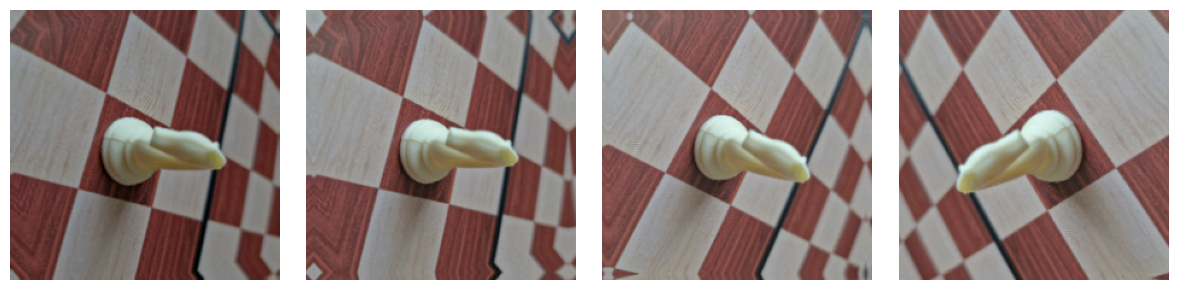

In [ ]:
# extracting a singular target photo
image = example_images[0]

# plotting multiple random iterations side-by-side
plt.figure(figsize=(12, 3))
for index in range(4):
    # generating varied augmented images dynamically
    augmented = augmentation(tf.expand_dims(image, 0), training=True)[0]
    plt.subplot(1, 4, index + 1)
    # clipping numeric ranges for safe display formatting
    plt.imshow(tf.cast(tf.clip_by_value(augmented, 0, 255), tf.uint8))
    plt.axis("off")

# resolving dimensional spacings
plt.tight_layout()
# outputting visualization outputs
plt.show()

The four random variations of the image shows slight spatial transformations and color adjustments.

9. Plotting accuracy curves over training epochs and computing final generalization scores.

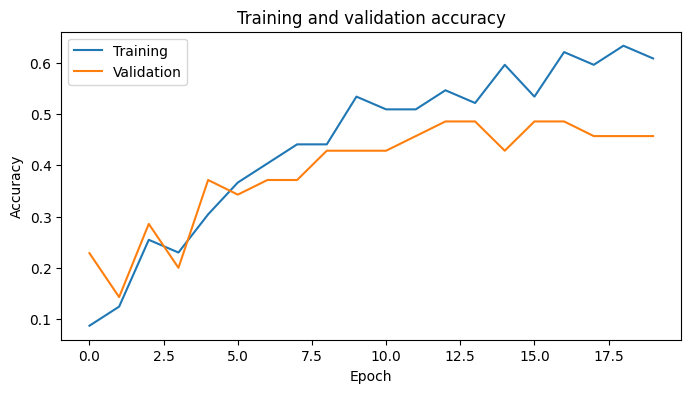

3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.3429 - loss: 1.8274
Test accuracy: 34.3%


In [23]:
# creating metric progress visualizations
plt.figure(figsize=(8, 4))
# plotting computed learning performance boundaries
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
# labeling dimensional axes
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and validation accuracy")
plt.legend()
# outputting charts
plt.show()

# processing metrics using test set evaluations
test_loss, test_accuracy = model2.evaluate(test_images)
# presenting resulting final metric values
print(f"Test accuracy: {test_accuracy:.1%}")

Comparing the training and validation lines showing steady training progress but revealing severe overfitting patterns. Observing the validation performance peaking at approximately 37% and terminating with a final evaluation test accuracy of 34.3% on unseen images.

In [29]:
# Importing numerical utilities and Colab file helpers
import numpy as np
from google.colab import files

# Uploading a custom photo from the local system
uploaded_photo = files.upload()
photo_path = next(iter(uploaded_photo))

# Loading the uploaded image and running model inference
image, _ = load_image(photo_path, 0)
probabilities = model2.predict(tf.expand_dims(image, 0), verbose=0)[0]

# Extracting the best predicted class index and printing the outcome
best = np.argmax(probabilities)
print("Prediction:", labels[best])
print(f"Model score: {probabilities[best]:.1%}")

Saving 7.jpg to 7 (1).jpg
Prediction: white_queen
Model score: 93.2%


## Model Performance Comparison, Conclusion & Recommendations

#### 1. Baseline vs. Augmented Model Comparison

- **Baseline Model (No Augmentation, No Dropout)**:
  - **Training Accuracy**: Climbed rapidly to **80.8%** by Epoch 10.
  - **Validation Accuracy**: Stagnated and fluctuated around **37.1%**.
  - **Test Accuracy**: Evaluated at **37.1%**.
  - **Observation**: This model exhibited severe **overfitting**. Since the training accuracy continued rising while validation metrics lagged behind, the network simply memorized the small set of training samples instead of learning generalizable features.

- **Augmented Model (With Dropout & Image Augmentations)**:
  - **Training Accuracy**: Reached **60.9%** at Epoch 20.
  - **Validation Accuracy**: Peaked around **45.7%** to **48.6%** before training halted via early stopping.
  - **Test Accuracy**: Evaluated at **34.3%**.
  - **Observation**: Introducing data augmentations (flips, rotations, zooms) and a `Dropout(0.2)` layer successfully slowed down training memorization (narrowing the generalization gap), but overall test performance remained low due to the extremely limited dataset size.

#### 2. Project Conclusion
We have built and compared two transfer learning pipelines using `MobileNetV2` to classify 12 distinct categories of chess pieces. While both models achieved incredibly high prediction confidence on specific clean test images (such as correctly identifying the `white_queen` with >92% confidence), generalization performance overall is capped (~34% to 37%) primarily due to the severe data scarcity (only 231 total images across 12 classes).

#### 3. Challenges Encountered
- **Data Scarcity**: With only about 15 to 23 images per class, the models lack sufficient variety to capture invariant features of each chess piece from different angles, lighting conditions, and background patterns.
- **Overfitting**: Standard pre-trained models are highly expressive, making them prone to memorizing small datasets rapidly.
- **Optimization vs. Generalization**: Although augmentation reduced the gap between training and validation scores, the absolute validation/test performance remained restricted.

#### 4. Recommendations for Future Improvements
- **Acquire More Data**: The single most effective remedy is to increase the dataset size to at least 100-200 images per class.
- **Fine-Tuning**: Once a larger dataset is secured, unfreezing the top layers of the `MobileNetV2` backbone and retraining with a very low learning rate (e.g., `1e-5`) could significantly boost domain-specific accuracy.
- **Alternative Backbones**: Test lighter architectures or specialized vision models (like ResNet or EfficientNet) to see if they extract more robust spatial features from chess boards.